In [49]:

import pandas as pd
from matplotlib import pyplot as plt
import warnings
warnings.filterwarnings('ignore')

In [50]:

df = pd.read_csv("insurance_data.csv")
df

,age,bought_insurance
0,22,0
1,25,0
2,47,1
3,52,0
4,46,1
5,56,1
6,55,0
7,60,1
8,62,1
9,61,1


In [51]:
df.age.min()

18

In [52]:
df.age.max()

62

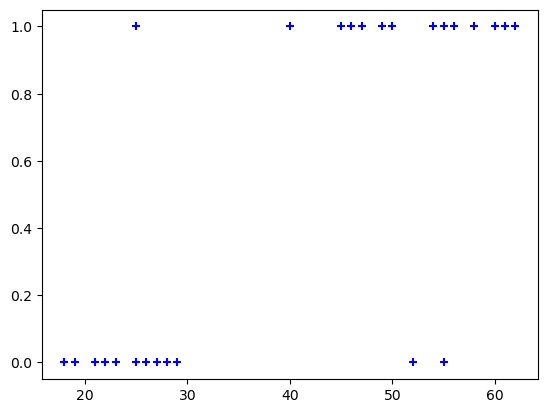

In [53]:

plt.scatter(df.age,df.bought_insurance,marker='+',color='blue')

plt.show()

In [54]:

from sklearn.model_selection import train_test_split

In [55]:

X_train, X_test, y_train, y_test = train_test_split(df[['age']],df.bought_insurance,train_size=0.8)

In [56]:

X_train.head()

,age
24,50
25,54
16,25
15,55
2,47


In [57]:

y_train.head()

24    1
25    1
16    1
15    1
2     1
Name: bought_insurance, dtype: int64

In [58]:

from sklearn.linear_model import LogisticRegression

model = LogisticRegression()

In [59]:

model.fit(X_train, y_train)

,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add a L2 penalty term and it is the default choice;- `'l1'`: add a L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'` and `l1_ratio` set to any float between 0 and 1 for `'penalty='elasticnet'`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation `) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"random_state random_state: int, RandomState instance, default=NoneUsed when ``solver`` == 'sag', 'saga' or 'liblinear' to shuffle thedata. See :term:`Glossary ` for details.",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default is 'lbfgs'.To choose a solver, you might want to consider the following aspects:- 'lbfgs' is a good default solver because it works reasonably well for a wide class of problems.- For :term:`mul

In [60]:

y_predicted = model.predict(X_test)
y_predicted

array([0, 1, 0, 0, 0, 0])

In [61]:

model.predict_proba(X_test)

array([[0.7875182 , 0.2124818 ],
       [0.05552537, 0.94447463],
       [0.72592498, 0.27407502],
       [0.85296032, 0.14703968],
       [0.8383518 , 0.1616482 ],
       [0.89031824, 0.10968176]])

In [62]:

print(model.score(X_test,y_test)*100)

100.0


In [63]:

y_predicted

array([0, 1, 0, 0, 0, 0])

In [64]:

y_test.values

array([0, 1, 0, 0, 0, 0])

In [65]:
model.coef_

array([[0.11199511]])

In [66]:
model.intercept_

array([-4.10990782])

In [67]:
import numpy as np


def sigmoid(x):
    return 1 / (1 + np.exp(-x))


def prediction_function(age):
    z = model.coef_ * age + model.intercept_
    y = sigmoid(z)
    return y


age = 30
res = prediction_function(age)
print(res)

[[0.32080941]]


In [68]:
age = 46
prediction_function(age)

array([[0.73921011]])

In [69]:
import numpy as np

ages = np.linspace(18, 62, 100)
probs = [prediction_function(a) for a in ages]
print(probs)


[array([[0.10968176]]), array([[0.11463769]]), array([[0.11978743]]), array([[0.12513581]]), array([[0.13068752]]), array([[0.13644713]]), array([[0.14241899]]), array([[0.14860724]]), array([[0.15501578]]), array([[0.1616482]]), array([[0.1685078]]), array([[0.17559753]]), array([[0.18291992]]), array([[0.19047711]]), array([[0.19827075]]), array([[0.20630201]]), array([[0.21457153]]), array([[0.22307936]]), array([[0.23182496]]), array([[0.24080715]]), array([[0.25002409]]), array([[0.25947324]]), array([[0.26915133]]), array([[0.27905439]]), array([[0.28917764]]), array([[0.29951556]]), array([[0.31006184]]), array([[0.32080941]]), array([[0.33175038]]), array([[0.34287611]]), array([[0.35417721]]), array([[0.36564352]]), array([[0.37726421]]), array([[0.38902772]]), array([[0.40092189]]), array([[0.41293393]]), array([[0.42505052]]), array([[0.43725783]]), array([[0.44954161]]), array([[0.46188724]]), array([[0.47427979]]), array([[0.4867041]]), array([[0.49914487]]), array([[0.511

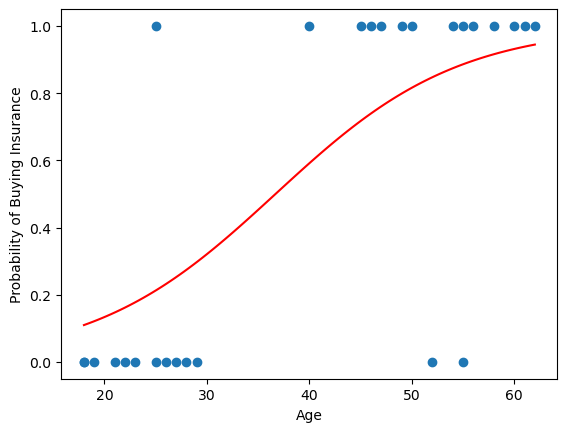

In [70]:
import matplotlib.pyplot as plt
import numpy as np


def sigmoid(x):
  return 1 / (1 + np.exp(-x))


def prediction_function(age):
  z = model.coef_ * age + model.intercept_
  return sigmoid(z)


# Create a smooth range of ages across your dataset
ages = np.linspace(df.age.min(), df.age.max(), 100)
probs = prediction_function(ages).ravel()  # ensures shape is (100,)

plt.scatter(df.age, df.bought_insurance)
plt.plot(ages, probs, color="red")
plt.xlabel("Age")
plt.ylabel("Probability of Buying Insurance")
plt.show()